<a href="https://colab.research.google.com/github/ShlokBagwe/Agri-AI-Bootcamp/blob/main/Agri_Day_3ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("atharvaingle/crop-recommendation-dataset")

print("Path to dataset files:", path)

100%|██████████| 63.7k/63.7k [00:00<00:00, 25.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/atharvaingle/crop-recommendation-dataset/versions/1


In [2]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score

csv_path = os.path.join(path, 'Crop_recommendation.csv')
df = pd.read_csv(csv_path)


In [3]:
water_demanding_crops = ['rice', 'papaya', 'coconut', 'jute', 'banana']
df['Needs Water'] = df['label'].isin(water_demanding_crops).astype(int)

In [4]:
X = df.drop(columns=['label', 'Needs Water'])
y = df['Needs Water']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [5]:
m = LogisticRegression(max_iter=1000).fit(X_train, y_train)

In [6]:
print(confusion_matrix(y_test, m.predict(X_test)))
print(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]))

[[320   7]
 [  6 107]]
0.9946956780601337


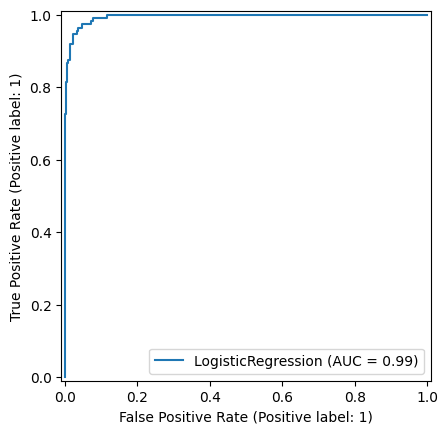

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(m, X_test, y_test)
plt.show()